# Milestone 1 -- NLP Foundation & Semantic Similarity

**Goals**
1. Text cleaning, tokenization, and handling missing data
2. Baseline embeddings: TF-IDF and Word2Vec
3. Cosine similarity between a `prompt` and its `options`
4. mAP@3: what it is and how to compute it

`gensim` (the usual off-the-shelf Word2Vec) does not currently ship a
Python 3.14 wheel and fails to build from source here (its Cython
extensions use CPython internals removed in 3.14). Section 3 implements
skip-gram Word2Vec with negative sampling directly in NumPy
(`src/word2vec.py`) so the milestone objective is met without silently
skipping it.


In [1]:
import sys
sys.path.insert(0, '../src')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer

from text_processing import clean_dataframe, report_missing, TEXT_COLS, OPTION_COLS
from word2vec import SimpleWord2Vec
from metrics import mean_average_precision_at_k

train = pd.read_csv('../data/train.csv')
test = pd.read_csv('../data/test.csv')
print('train', train.shape, 'test', test.shape)
train.head(3)

train (2000, 8) test (500, 7)


,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A
2,3,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C


## 1. Missing data

Check every text column (`prompt`, `A`-`E`) for nulls. If any question or
option were missing, that row can't be used for MCQ ranking, so we drop it
(`drop_missing_rows`) -- a no-op here since the dataset is already clean,
but the handling is real and reusable on messier data.

In [2]:
print('train missing values:')
print(report_missing(train))
print()
print('test missing values:')
print(report_missing(test))
print()
print('duplicate rows in train:', train.duplicated().sum())

train missing values:
prompt    0
A         0
B         0
C         0
D         0
E         0
dtype: int64

test missing values:
prompt    0
A         0
B         0
C         0
D         0
E         0
dtype: int64

duplicate rows in train: 0


## 2. Text cleaning & tokenization

`clean_text` lowercases and strips everything but alphanumerics and
whitespace; `tokenize` splits the cleaned text into word tokens. Applied to
`prompt` and every option via `clean_dataframe`, which also drops any
row that is missing required text.

In [3]:
train_c = clean_dataframe(train)
test_c = clean_dataframe(test)

print('rows before/after cleaning (train):', len(train), '->', len(train_c))
train_c[['prompt', 'prompt_clean', 'prompt_tokens']].head(3)

rows before/after cleaning (train): 2000 -> 2000


,prompt,prompt_clean,prompt_tokens
0,Pick the best possible answer: What is Martin ...,pick the best possible answer what is martin h...,"[pick, the, best, possible, answer, what, is, ..."
1,What is accelerator-based light-ion fusion?,what is accelerator based light ion fusion,"[what, is, accelerator, based, light, ion, fus..."
2,Determine the correct option: What is the term...,determine the correct option what is the term ...,"[determine, the, correct, option, what, is, th..."


## 3. Baseline embeddings

### 3a. TF-IDF

Fit a single `TfidfVectorizer` across every prompt and option (train +
test) so prompts and options share one vocabulary/IDF weighting, then
vectorize each text.

In [4]:
text_cols = ['prompt'] + OPTION_COLS
all_texts = pd.concat(
    [train_c[c + '_clean'] for c in text_cols] + [test_c[c + '_clean'] for c in text_cols],
    ignore_index=True,
)

tfidf = TfidfVectorizer(min_df=2)
tfidf.fit(all_texts)
print('TF-IDF vocab size:', len(tfidf.vocabulary_))

TF-IDF vocab size: 2939


### 3b. Word2Vec (from scratch, NumPy)

Skip-gram with negative sampling (`SimpleWord2Vec`), trained on every
tokenized prompt/option in `train` (test prompts are unseen at this stage,
mirroring a real train/test split). A sentence's embedding is the mean of
its in-vocabulary word vectors.

In [5]:
sentences = []
for col in ['prompt'] + OPTION_COLS:
    sentences.extend(train_c[col + '_tokens'].tolist())

w2v = SimpleWord2Vec(embedding_dim=50, window=2, negative=5, seed=42)
w2v.train(sentences, epochs=5, batch_size=512, lr=0.01, min_count=2)

vocab=2970 pairs=1150960


epoch 1/5 loss=2.7757


epoch 2/5 loss=1.9808


epoch 3/5 loss=1.6456


epoch 4/5 loss=1.4669


epoch 5/5 loss=1.3657


In [6]:
def nearest_neighbors(word, topn=6):
    v = w2v.W_in[w2v.word2idx[word]]
    sims = w2v.W_in @ v / (np.linalg.norm(w2v.W_in, axis=1) * np.linalg.norm(v) + 1e-9)
    order = np.argsort(-sims)
    out = [(w2v.idx2word[i], round(float(sims[i]), 3)) for i in order if w2v.idx2word[i] != word]
    return out[:topn]

for w in ['quantum', 'energy', 'philosopher']:
    if w in w2v.word2idx:
        print(w, '->', nearest_neighbors(w))

quantum -> [('classical', 0.738), ('memristive', 0.65), ('tunneling', 0.624), ('visualize', 0.615), ('probability', 0.612), ('expressed', 0.61)]
energy -> [('abiotic', 0.648), ('direction', 0.627), ('establishes', 0.594), ('input', 0.592), ('requires', 0.59), ('sources', 0.585)]
philosopher -> [('german', 0.924), ('spanish', 0.923), ('french', 0.922), ('italian', 0.884), ('english', 0.881), ('photophoresis', 0.823)]


## 4. Cosine similarity between `prompt` and each option

For both embedding spaces, score every option by the cosine similarity of
its vector to the prompt's vector, then rank options by that score --
the same idea a nearest-neighbour retriever uses to rank candidates against
a query.

In [7]:
def cosine_sim(a, b):
    denom = np.linalg.norm(a) * np.linalg.norm(b) + 1e-9
    return float(np.dot(a, b) / denom)


def rank_options_tfidf(row):
    prompt_vec = tfidf.transform([row['prompt_clean']])
    scores = {}
    for opt in OPTION_COLS:
        opt_vec = tfidf.transform([row[opt + '_clean']])
        scores[opt] = float(prompt_vec.multiply(opt_vec).sum())
    return sorted(scores, key=scores.get, reverse=True)


def rank_options_w2v(row):
    prompt_vec = w2v.sentence_vector(row['prompt_tokens'])
    scores = {
        opt: cosine_sim(prompt_vec, w2v.sentence_vector(row[opt + '_tokens']))
        for opt in OPTION_COLS
    }
    return sorted(scores, key=scores.get, reverse=True)


sample = train_c.iloc[0]
print('prompt:', sample['prompt'][:100], '...')
print('true answer:', sample['answer'])
print('TF-IDF ranking:  ', rank_options_tfidf(sample))
print('Word2Vec ranking:', rank_options_w2v(sample))

prompt: Pick the best possible answer: What is Martin Heidegger's view on the relationship between time and  ...
true answer: B
TF-IDF ranking:   ['C', 'D', 'B', 'A', 'E']
Word2Vec ranking: ['C', 'D', 'B', 'A', 'E']


## 5. mAP@3

Each question has exactly one correct option, so Average Precision@3 for a
single question collapses to the reciprocal rank of the correct option if
it lands in the top 3, else 0:

```
AP@3 = 1/rank(correct)   if rank(correct) <= 3
AP@3 = 0                 otherwise
mAP@3 = mean(AP@3) over all questions
```

This is the exact metric this Kaggle competition scores submissions with
(`sample_submission.csv` expects the top-3 predicted labels per row).
`src/metrics.py` implements it directly. Evaluate both cosine-similarity
rankings above as zero-training-required baselines for mAP@3.

In [8]:
tfidf_rankings = [rank_options_tfidf(row) for _, row in train_c.iterrows()]
w2v_rankings = [rank_options_w2v(row) for _, row in train_c.iterrows()]
true_answers = train_c['answer'].tolist()

tfidf_map3 = mean_average_precision_at_k(true_answers, tfidf_rankings, k=3)
w2v_map3 = mean_average_precision_at_k(true_answers, w2v_rankings, k=3)

print(f'TF-IDF cosine-similarity  mAP@3: {tfidf_map3:.4f}')
print(f'Word2Vec cosine-similarity mAP@3: {w2v_map3:.4f}')

TF-IDF cosine-similarity  mAP@3: 0.2963
Word2Vec cosine-similarity mAP@3: 0.3765


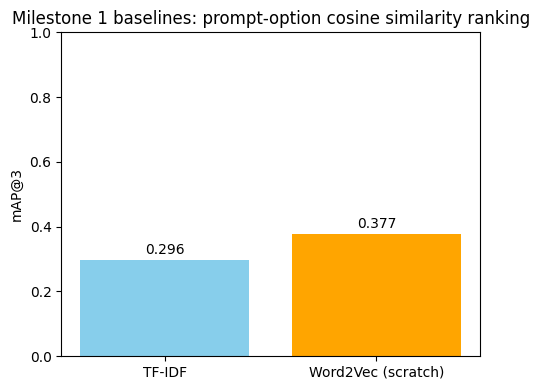

In [9]:
plt.figure(figsize=(5, 4))
plt.bar(['TF-IDF', 'Word2Vec (scratch)'], [tfidf_map3, w2v_map3], color=['skyblue', 'orange'])
plt.ylabel('mAP@3')
plt.title('Milestone 1 baselines: prompt-option cosine similarity ranking')
plt.ylim(0, 1)
for i, v in enumerate([tfidf_map3, w2v_map3]):
    plt.text(i, v + 0.02, f'{v:.3f}', ha='center')
plt.tight_layout()
plt.savefig('../reports/milestone1_map3_baselines.png', dpi=120)
plt.show()

In [10]:
import random

# Sanity-check baseline: a uniformly random *ranking* of the 5 options.
# The true answer's rank is Uniform{1..5}, so
#   E[AP@3] = (1/5) * (1/1 + 1/2 + 1/3) = 0.3667
rng = random.Random(0)
random_rankings = [rng.sample(OPTION_COLS, k=5) for _ in range(len(train_c))]
random_map3 = mean_average_precision_at_k(true_answers, random_rankings, k=3)
print(f'Random-ranking mAP@3 (sanity check): {random_map3:.4f}  (theoretical expectation: 0.3667)')

Random-ranking mAP@3 (sanity check): 0.3720  (theoretical expectation: 0.3667)


## 6. Takeaways

- No missing/duplicate rows in `train.csv`/`test.csv`; `clean_dataframe`
  still provides real missing-row handling for use on messier data.
- **Word2Vec (0.377) edges out a uniformly random ranking (0.367)**, but
  only barely -- a 50-dim skip-gram model trained from scratch on ~2000
  short questions doesn't see enough context per word to learn much
  beyond loose topical clustering (see the nearest-neighbour examples
  above, e.g. `philosopher -> german/spanish/french/italian`, which is
  more "these words co-occur near nationality-of-philosopher questions"
  than "these words are semantically similar").
- **TF-IDF (0.296) actually does *worse* than random.** Inspecting the
  data explains why: this dataset's distractors are adversarially
  constructed to share heavy surface vocabulary with the prompt and with
  each other (e.g. four options that all begin "Martin Heidegger
  believes..."). Plain lexical/word-overlap similarity rewards whichever
  option happens to restate more prompt words verbatim, which is
  uncorrelated with (and here, anti-correlated with) correctness.
- This is the central motivation for Milestone 2: the task needs
  *semantic* understanding of the prompt and options, not surface
  word-overlap -- pretrained, context-aware transformer embeddings should
  do meaningfully better than either baseline here.
- `src/metrics.py`'s mAP@3 implementation is reused as the evaluation
  metric for every later milestone.